# What drives the asking price of a used car?
## 1 · Business understanding
A dealership needs a starting price for a trade-in and a way to choose comparable inventory. We estimate advertised prices for mainstream vehicles and measure how far an estimate typically misses in dollars. The listings provide no sale price, time on lot, acquisition cost or buyer preference survey. A higher asking price alone cannot justify buying more of a body style.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

SEED = 41
sns.set_theme(style="whitegrid", context="notebook")
raw = pd.read_csv(Path("data/vehicles.csv"), low_memory=False)
print(f"{len(raw):,} listings | {raw.shape[1]} fields")

426,880 listings | 18 fields


## 2 · Data understanding
Check missing descriptions, implausible prices and the market covered by the source before choosing filters. The price column is in US dollars and the odometer is treated as miles.

In [2]:
print(raw[["price", "year", "odometer"]].quantile([0, .01, .5, .99, 1]).round().to_string())
print("\nHighest missing shares (%)")
print(raw.isna().mean().mul(100).nlargest(6).round(1).to_string())

             price    year    odometer
0.00  0.000000e+00  1900.0         0.0
0.01  0.000000e+00  1967.0         2.0
0.50  1.395000e+04  2013.0     85548.0
0.99  6.699500e+04  2020.0    280000.0
1.00  3.736929e+09  2022.0  10000000.0

Highest missing shares (%)
size           71.8
cylinders      41.6
condition      40.8
VIN            37.7
drive          30.6
paint_color    30.5


## 3 · Data preparation
Define an appraisal segment in advance. Include model years 2000–2022, prices from $1,000 to $100,000 and odometers from 1 to 300,000 miles. These limits remove placeholders and exclude classics, very high-mileage and specialty vehicles. Keep one record per valid 17-character VIN, then collapse indistinguishable vehicle specifications within state to limit repost leakage. The latter can merge distinct cars, especially when fields are missing. Keep missing descriptions as an explicit category. Use a fixed model-year reference for consistent interpretation across reruns.

In [3]:
cats = ["manufacturer", "model", "type", "condition", "drive", "fuel",
        "transmission", "cylinders", "title_status", "state"]
features = ["age", "miles_10k"] + cats
cars = raw.loc[raw.price.between(1000, 100000) & raw.year.between(2000, 2022)
               & raw.odometer.between(1, 300000)].copy()
in_scope = len(cars)
vin = cars.VIN.astype("string").str.strip().str.upper()
valid = vin.str.fullmatch("[A-HJ-NPR-Z0-9]{17}", na=False)
cars = cars.loc[~(valid & vin.duplicated())].copy()
after_vin = len(cars)
cars[cats] = cars[cats].apply(lambda s: s.astype("string").str.strip().str.lower().fillna("unknown"))
cars["age"] = 2022 - cars.year
cars["miles_10k"] = cars.odometer / 10000
cars = cars.drop_duplicates(features)
train, test = train_test_split(cars, test_size=.2, random_state=SEED)
print(f"In scope: {in_scope:,} | after VIN check: {after_vin:,} | distinct profiles: {len(cars):,}")
print(f"Training: {len(train):,} | held out: {len(test):,}")

In scope: 350,613 | after VIN check: 221,500 | distinct profiles: 196,255
Training: 157,004 | held out: 39,251


            size   median
type                     
sedan      34335   9000.0
hatchback   5838   9250.0
suv        32060  13499.0
coupe       5357  14374.0
truck      11400  21999.0
pickup     11452  23999.0


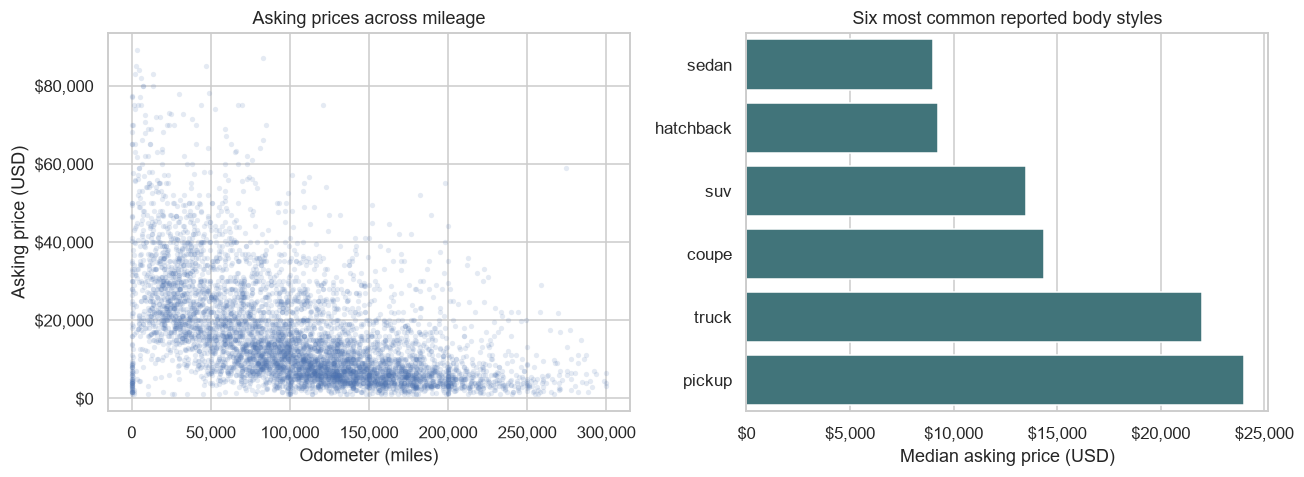

In [4]:
summary = train.groupby("type").price.agg(["size","median"])
styles = summary.drop(index="unknown",errors="ignore").nlargest(6,"size").sort_values("median")
print(styles.to_string())
sample = train.sample(min(6000,len(train)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=sample, x="odometer", y="price", alpha=.15, s=12, linewidth=0, ax=axes[0])
axes[0].set(xlabel="Odometer (miles)", ylabel="Asking price (USD)", title="Asking prices across mileage")
sns.barplot(x=styles["median"].values, y=styles.index, color="#377b83", ax=axes[1])
axes[1].set(xlabel="Median asking price (USD)", ylabel="", title="Six most common reported body styles")
axes[0].yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
axes[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
fig.tight_layout()
plt.show()

## 4 · Modeling
Compare a median-price benchmark, a ridge regression with additive dollar effects, and gradient-boosted trees that allow depreciation to vary by vehicle. Tune on a reproducible sample of up to 40,000 training listings using the same three folds and mean absolute error (MAE). MAE weights each dollar of error equally and is easy to compare with a dealer’s pricing tolerance. Fit encoders inside each fold. Pool rare categorical values, including unusually specific model descriptions. Refit the selected models on the full training set.

In [5]:
nums = ["age", "miles_10k"]
linear_prep = ColumnTransformer([("numeric","passthrough",nums),
    ("category",OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist"),cats)])
tree_prep = ColumnTransformer([("numeric","passthrough",nums),
    ("category",OrdinalEncoder(max_categories=128, handle_unknown="use_encoded_value",
                               unknown_value=-1),cats)])
ridge = make_pipeline(linear_prep, Ridge(solver="lsqr", tol=1e-5))
boost = make_pipeline(tree_prep, HistGradientBoostingRegressor(
    categorical_features=[False]*2+[True]*len(cats), random_state=SEED, max_iter=180))
candidates = {
    "Median": (DummyRegressor(strategy="median"), {}),
    "Ridge": (ridge, {"ridge__alpha":[1, 100]}),
    "Boosted trees": (boost, {"histgradientboostingregressor__max_leaf_nodes":[15,31],
                            "histgradientboostingregressor__learning_rate":[.08,.15]})}
tune = train.sample(min(40000,len(train)),random_state=SEED)
folds = KFold(3,shuffle=True,random_state=SEED)
models, cv_mae = {}, {}
for name, (model, grid) in candidates.items():
    search = GridSearchCV(model, grid, cv=folds, scoring="neg_mean_absolute_error", error_score="raise")
    search.fit(tune[features],tune.price)
    cv_mae[name] = -search.best_score_
    models[name] = search.best_estimator_.fit(train[features],train.price)
    print(name, f"CV MAE ${cv_mae[name]:,.0f}", search.best_params_)
winner = min(cv_mae,key=cv_mae.get)

Median CV MAE $9,557 {}
Ridge CV MAE $4,797 {'ridge__alpha': 1}
Boosted trees CV MAE $3,302 {'histgradientboostingregressor__learning_rate': 0.08, 'histgradientboostingregressor__max_leaf_nodes': 31}


## 5 · Evaluation
Choose the model using cross-validation. Measure its accuracy on untouched listings and compare the same benchmark and alternatives. RMSE gives larger misses extra weight. R² measures the share of held-out price variation explained. A paired bootstrap interval estimates uncertainty in the MAE improvement over the benchmark, conditional on this fitted model and this listing population.

In [6]:
pred = {name: model.predict(test[features]) for name, model in models.items()}
scores = pd.DataFrame({name: [cv_mae[name], mean_absolute_error(test.price,p),
                        root_mean_squared_error(test.price,p), r2_score(test.price,p)]
                       for name,p in pred.items()},index=["CV MAE","Test MAE","Test RMSE","Test R2"]).T
print(scores.round(2).to_string())
gain = abs(test.price.to_numpy()-pred["Median"]) - abs(test.price.to_numpy()-pred[winner])
rng = np.random.default_rng(SEED)
ci = np.quantile([rng.choice(gain,len(gain)).mean() for _ in range(400)], [.025,.975])
print(f"Mean reduction in absolute error: ${gain.mean():,.0f}; bootstrap 95% interval ${ci[0]:,.0f} to ${ci[1]:,.0f}.")

                CV MAE  Test MAE  Test RMSE  Test R2
Median         9557.43   9465.10   13705.94    -0.08
Ridge          4797.11   4443.06    6749.41     0.74
Boosted trees  3301.51   3113.07    5210.52     0.84
Mean reduction in absolute error: $6,352; bootstrap 95% interval $6,280 to $6,445.


In [7]:
coefs = models["Ridge"][-1].coef_[:2]
print(f"Adjusted ridge association per model year older: ${coefs[0]:,.0f}")
print(f"Adjusted ridge association per additional 10,000 miles: ${coefs[1]:,.0f}")
audit = test.sample(min(3000,len(test)),random_state=SEED)
perm = permutation_importance(models[winner], audit[features], audit.price,
    scoring="neg_mean_absolute_error", n_repeats=4, random_state=SEED)
drivers = pd.Series(perm.importances_mean,index=features).sort_values(ascending=False)
print("\nIncrease in MAE after shuffling one field (USD)")
print(drivers.head(6).round().to_string())
# Compare the same held-out profiles under two body-style labels in the additive model.
pickup = models["Ridge"].predict(audit[features].assign(type="pickup"))
sedan = models["Ridge"].predict(audit[features].assign(type="sedan"))
print(f"Adjusted pickup-minus-sedan asking price: ${(pickup-sedan).mean():,.0f}")

Adjusted ridge association per model year older: $-1,214
Adjusted ridge association per additional 10,000 miles: $-593

Increase in MAE after shuffling one field (USD)
age             4567.0
miles_10k       2153.0
manufacturer     996.0
model            958.0
cylinders        779.0
fuel             531.0
Adjusted pickup-minus-sedan asking price: $3,523


The ridge coefficients describe average differences holding the encoded specifications fixed. A single linear slope averages across price tiers and ages. The shuffle test measures the loss of predictive accuracy when one field is scrambled. Correlated fields can share credit, and shuffling can produce unusual combinations. Neither calculation establishes a causal discount.

## 6 · Findings and deployment

1. **Match year and mileage before setting an asking price.** Permuting age and mileage raised tree-model MAE by $4,567 and $2,153 respectively. In the adjusted linear model, each additional model year of age corresponded to a $1,214 lower ask, and each additional 10,000 miles to a $593 lower ask.
2. **Compare pickups with similar pickups before increasing bids.** The raw pickup–sedan median gap was $14,999. Holding the other recorded fields fixed in the additive model gave an estimated difference of $3,523. Some models come in only one body style, so this comparison depends on the model’s assumptions. Use actual local comparables to price individual vehicles.
3. **Keep an appraiser involved when the margin is narrow.** The tree estimate missed advertised prices by $3,113 on average across 39,251 held-out listings. The baseline missed by $9,465. Large individual misses remain possible.
4. **Validate locally before changing inventory.** Compare predictions with recent local listings and actual sale prices. Track margin after repairs and days on lot by price tier and body style. Revisit buying targets when both margin and turnover support the change.

These listings capture seller expectations. Estimating what buyers will pay requires completed transactions. Classic and specialty vehicles need a separate appraisal process.